<a href="https://colab.research.google.com/github/andalive/AlProg/blob/main/CMAPSS/CMAPSS_BPNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**IMPORT LIBRARY**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

##**MEMUAT DATASET**

In [ ]:
column_names = ['unit_number', 'cycles',
                'opSet_1', 'opSet_2', 'opSet_3'] + \
               [f'sensor_{i}' for i in range(1, 22)]  # Sensor_1 hingga Sensor_21

# data training
train1_df = pd.read_csv('train_FD001.txt', sep='\s+', header=None, names=column_names)
train1_df

,unit_number,cycles,opSet_1,opSet_2,opSet_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20626,100,196,-0.0004,-0.0003,100.0,518.67,643.49,1597.98,1428.63,14.62,...,519.49,2388.26,8137.60,8.4956,0.03,397,2388,100.0,38.49,22.9735
20627,100,197,-0.0016,-0.0005,100.0,518.67,643.54,1604.50,1433.58,14.62,...,519.68,2388.22,8136.50,8.5139,0.03,395,2388,100.0,38.30,23.1594
20628,100,198,0.0004,0.0000,100.0,518.67,643.42,1602.46,1428.18,14.62,...,520.01,2388.24,8141.05,8.5646,0.03,398,2388,100.0,38.44,22.9333
20629,100,199,-0.0011,0.0003,100.0,518.67,643.23,1605.26,1426.53,14.62,...,519.67,2388.23,8139.29,8.5389,0.03,395,2388,100.0,38.29,23.0640


In [ ]:
# data testing
test1_df = pd.read_csv('train_FD001.txt', sep='\s+', header=None, names=column_names)
test1_df

,unit_number,cycles,opSet_1,opSet_2,opSet_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20626,100,196,-0.0004,-0.0003,100.0,518.67,643.49,1597.98,1428.63,14.62,...,519.49,2388.26,8137.60,8.4956,0.03,397,2388,100.0,38.49,22.9735
20627,100,197,-0.0016,-0.0005,100.0,518.67,643.54,1604.50,1433.58,14.62,...,519.68,2388.22,8136.50,8.5139,0.03,395,2388,100.0,38.30,23.1594
20628,100,198,0.0004,0.0000,100.0,518.67,643.42,1602.46,1428.18,14.62,...,520.01,2388.24,8141.05,8.5646,0.03,398,2388,100.0,38.44,22.9333
20629,100,199,-0.0011,0.0003,100.0,518.67,643.23,1605.26,1426.53,14.62,...,519.67,2388.23,8139.29,8.5389,0.03,395,2388,100.0,38.29,23.0640


#**EDA (Exploratory Data Analysis)**

###**A) Struktur Data**

In [ ]:
# Meninjau jumlah baris dan kolom dataset
print(f"Ukuran dataset: {train1_df.shape}\n")

# Meninjau jenis data tiap kolom (numerikal/kategorikal)
print("Info 'train_FD001.txt' data:\n")
train1_df.info()

Ukuran dataset: (20631, 26)

Info 'train_FD001.txt' data:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20631 entries, 0 to 20630
Data columns (total 26 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   unit_number  20631 non-null  int64  
 1   cycles       20631 non-null  int64  
 2   opSet_1      20631 non-null  float64
 3   opSet_2      20631 non-null  float64
 4   opSet_3      20631 non-null  float64
 5   sensor_1     20631 non-null  float64
 6   sensor_2     20631 non-null  float64
 7   sensor_3     20631 non-null  float64
 8   sensor_4     20631 non-null  float64
 9   sensor_5     20631 non-null  float64
 10  sensor_6     20631 non-null  float64
 11  sensor_7     20631 non-null  float64
 12  sensor_8     20631 non-null  float64
 13  sensor_9     20631 non-null  float64
 14  sensor_10    20631 non-null  float64
 15  sensor_11    20631 non-null  float64
 16  sensor_12    20631 non-null  float64
 17  sensor_13    20631 non-null  

###**B) Peninjuaan Data Hilang, Duplikat, dan Kategori Unik Fitur**

(1) **Data Hilang**

In [ ]:
# Mengidentifikasi jumlah nilai yang hilang tiap kolom
missing_vals = train1_df.isnull().sum()
missing_percentage = (missing_vals / len(train1_df)) * 100
missing_vals[missing_vals > 0]

missing_data = pd.DataFrame({
    'Missing Values': missing_vals,
    'Persentase': missing_percentage
}).sort_values(by='Missing Values', ascending=False)

# Memuat jumlah nilai yang hilang
missing_data[missing_data['Missing Values'] > 0]

,Missing Values,Persentase


Semua data lengkap, tidak ada yang bernialai NaN (*missing value*).

(2) **Data Duplikat**

In [ ]:
# Mengidentifikasi baris duplikat
duplicate_rows = train1_df.duplicated()

print(f"Info baris duplikat: {duplicate_rows.sum()}\n")
print(train1_df[duplicate_rows])

Info baris duplikat: 0

Empty DataFrame
Columns: [unit_number, cycles, opSet_1, opSet_2, opSet_3, sensor_1, sensor_2, sensor_3, sensor_4, sensor_5, sensor_6, sensor_7, sensor_8, sensor_9, sensor_10, sensor_11, sensor_12, sensor_13, sensor_14, sensor_15, sensor_16, sensor_17, sensor_18, sensor_19, sensor_20, sensor_21]
Index: []

[0 rows x 26 columns]


Tidak ditemukan adanya duplikasi baris, sehingga tidak ada proses imputasi baris pada dataset.

(3) **Fitur Unik**

In [ ]:
# Mengidentifikasi fitur unik
print(f"Uniqe categories fitur train1_df:\n\n{train1_df.nunique()}\n")

Uniqe categories fitur train1_df:

unit_number     100
cycles          362
opSet_1         158
opSet_2          13
opSet_3           1
sensor_1          1
sensor_2        310
sensor_3       3012
sensor_4       4051
sensor_5          1
sensor_6          2
sensor_7        513
sensor_8         53
sensor_9       6403
sensor_10         1
sensor_11       159
sensor_12       427
sensor_13        56
sensor_14      6078
sensor_15      1918
sensor_16         1
sensor_17        13
sensor_18         1
sensor_19         1
sensor_20       120
sensor_21      4745
dtype: int64



Didapati bahwa "opSet3", "sensor_1", "sensor_5", "sensor_10", "sensor_16", "sensor_18", dan "sensor_19" memiliki hanya 1 nilai unik. Fitur-fitur tersebut dapat diimputasi.

###**C) Analisa Distribusi Fitur dan Korelasi**

In [ ]:
# Analisa deskriptif dataset
train1_df.describe(include="all").T

,count,mean,std,min,25%,50%,75%,max
unit_number,20631.0,51.506568,2.922763e+01,1.0000,26.0000,52.0000,77.0000,100.0000
cycles,20631.0,108.807862,6.888099e+01,1.0000,52.0000,104.0000,156.0000,362.0000
opSet_1,20631.0,-0.000009,2.187313e-03,-0.0087,-0.0015,0.0000,0.0015,0.0087
opSet_2,20631.0,0.000002,2.930621e-04,-0.0006,-0.0002,0.0000,0.0003,0.0006
opSet_3,20631.0,100.000000,0.000000e+00,100.0000,100.0000,100.0000,100.0000,100.0000
sensor_1,20631.0,518.670000,6.537152e-11,518.6700,518.6700,518.6700,518.6700,518.6700
sensor_2,20631.0,642.680934,5.000533e-01,641.2100,642.3250,642.6400,643.0000,644.5300
sensor_3,20631.0,1590.523119,6.131150e+00,1571.0400,1586.2600,1590.1000,1594.3800,1616.9100
sensor_4,20631.0,1408.933782,9.000605e+00,1382.2500,1402.3600,1408.0400,1414.5550,1441.4900
sensor_5,20631.0,14.620000,3.394700e-12,14.6200,14.6200,14.6200,14.6200,14.6200


#**DATA PREPROCESSING**

###**A) Penanganan Fitur Unik**

In [ ]:
# drop kolom dengan fitur unik = 1
train1_df.drop(columns=['opSet_3', 'sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19'], inplace=True)
train1_df.head()

,unit_number,cycles,opSet_1,opSet_2,sensor_2,sensor_3,sensor_4,sensor_6,sensor_7,sensor_8,sensor_9,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_17,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,641.82,1589.70,1400.60,21.61,554.36,2388.06,9046.19,47.47,521.66,2388.02,8138.62,8.4195,392,39.06,23.4190
1,1,2,0.0019,-0.0003,642.15,1591.82,1403.14,21.61,553.75,2388.04,9044.07,47.49,522.28,2388.07,8131.49,8.4318,392,39.00,23.4236
2,1,3,-0.0043,0.0003,642.35,1587.99,1404.20,21.61,554.26,2388.08,9052.94,47.27,522.42,2388.03,8133.23,8.4178,390,38.95,23.3442
3,1,4,0.0007,0.0000,642.35,1582.79,1401.87,21.61,554.45,2388.11,9049.48,47.13,522.86,2388.08,8133.83,8.3682,392,38.88,23.3739
4,1,5,-0.0019,-0.0002,642.37,1582.85,1406.22,21.61,554.00,2388.06,9055.15,47.28,522.19,2388.04,8133.80,8.4294,393,38.90,23.4044


###**C) Identifikasi RUL untuk Dataset**

In [ ]:
# Nilai maksimum dari "engine unit_number" untuk setiap siklus (cycle)
train1_df.groupby("cycles")["unit_number"].max()

,unit_number
cycles,
1,100
2,100
3,100
4,100
5,100
...,...
358,69
359,69
360,69


In [ ]:
## Menentukan cylce tertinggi pada satu mesin pada "unit_number"
max_cycle = train1_df["cycles"].max()
max_unit = train1_df.loc[train1_df["cycles"] == max_cycle, "unit_number"].values[0]
print(f"Siklus mesin tertinggi sebesar: {max_cycle} pada mesin ke-{max_unit}")

Siklus mesin tertinggi sebesar: 362 pada mesin ke-69


**Plot Data Train FD001**

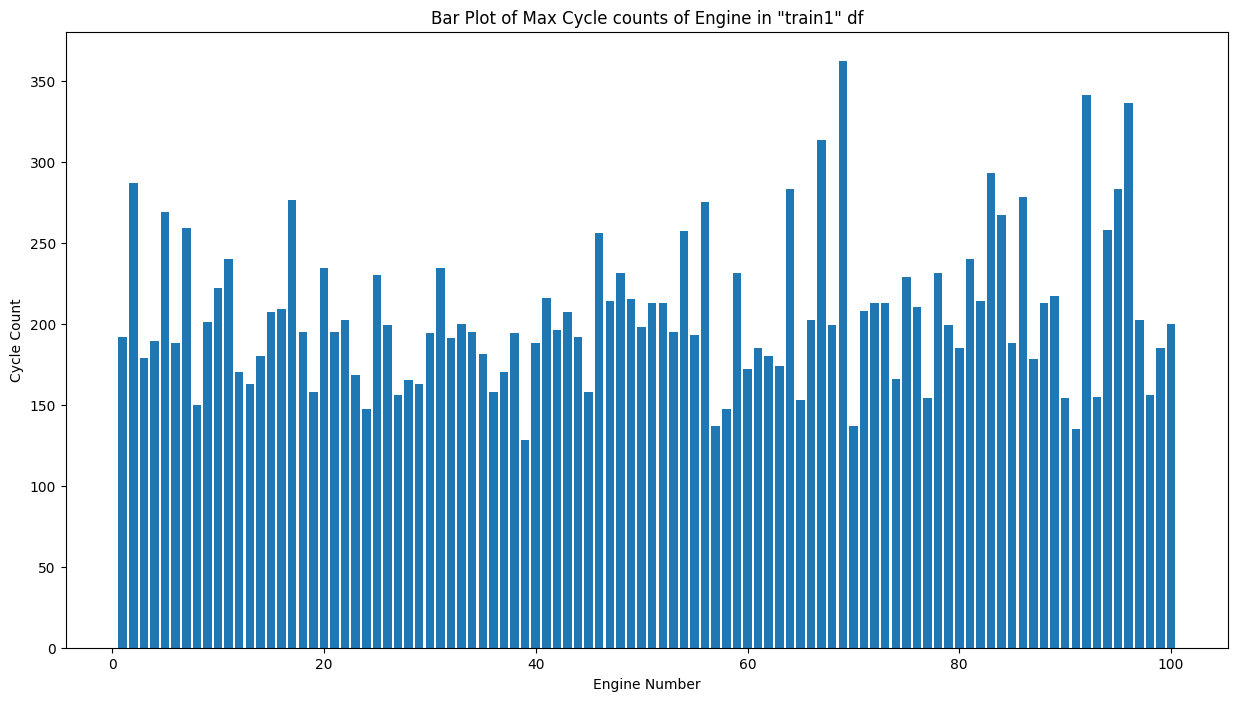

In [ ]:
plt.figure(figsize=(15, 8))
plt.bar(train1_df['unit_number'],train1_df['cycles'])

plt.xlabel('Engine Number')
plt.ylabel('Cycle Count')
plt.title('Bar Plot of Max Cycle counts of Engine in "train1" df')

plt.show()

**Kalkulasi RUL**

In [ ]:
# Kalkulasi RUL + merge hasilnya
def Calculate_RUL(df):
    max_cycles = df.groupby('unit_number')['cycles'].max()
    merged = df.merge(max_cycles.to_frame(name='max_time_cycle'), left_on='unit_number',right_index=True)
    merged["RUL"] = merged["max_time_cycle"] - merged['cycles']
    merged = merged.drop("max_time_cycle", axis=1)
    return merged

In [ ]:
train1_df=Calculate_RUL(train1_df)

In [ ]:
train1_df

,unit_number,cycles,opSet_1,opSet_2,sensor_2,sensor_3,sensor_4,sensor_6,sensor_7,sensor_8,sensor_9,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_17,sensor_20,sensor_21,RUL
0,1,1,-0.0007,-0.0004,641.82,1589.70,1400.60,21.61,554.36,2388.06,9046.19,47.47,521.66,2388.02,8138.62,8.4195,392,39.06,23.4190,191
1,1,2,0.0019,-0.0003,642.15,1591.82,1403.14,21.61,553.75,2388.04,9044.07,47.49,522.28,2388.07,8131.49,8.4318,392,39.00,23.4236,190
2,1,3,-0.0043,0.0003,642.35,1587.99,1404.20,21.61,554.26,2388.08,9052.94,47.27,522.42,2388.03,8133.23,8.4178,390,38.95,23.3442,189
3,1,4,0.0007,0.0000,642.35,1582.79,1401.87,21.61,554.45,2388.11,9049.48,47.13,522.86,2388.08,8133.83,8.3682,392,38.88,23.3739,188
4,1,5,-0.0019,-0.0002,642.37,1582.85,1406.22,21.61,554.00,2388.06,9055.15,47.28,522.19,2388.04,8133.80,8.4294,393,38.90,23.4044,187
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20626,100,196,-0.0004,-0.0003,643.49,1597.98,1428.63,21.61,551.43,2388.19,9065.52,48.07,519.49,2388.26,8137.60,8.4956,397,38.49,22.9735,4
20627,100,197,-0.0016,-0.0005,643.54,1604.50,1433.58,21.61,550.86,2388.23,9065.11,48.04,519.68,2388.22,8136.50,8.5139,395,38.30,23.1594,3
20628,100,198,0.0004,0.0000,643.42,1602.46,1428.18,21.61,550.94,2388.24,9065.90,48.09,520.01,2388.24,8141.05,8.5646,398,38.44,22.9333,2
20629,100,199,-0.0011,0.0003,643.23,1605.26,1426.53,21.61,550.68,2388.25,9073.72,48.39,519.67,2388.23,8139.29,8.5389,395,38.29,23.0640,1


**Meninjau Korelasi antar Fitur**

In [ ]:
def heat_map(df):
    sns.heatmap(df.corr(),annot=True,linewidths=0.2)
    fig=plt.gcf()
    fig.set_size_inches(20,20)
    plt.show()

#**MODEL BPNN**